# 06 · Final Evaluation, Robustness & Reproducibility

**Research question 5:** *How sensitive are the conclusions to uncertainty, model choice, and the split?*

Notebook 04 produced one held-out estimate per policy, from one 12,800-customer test set. With a noisy outcome like spend, a single split can be lucky or unlucky. This notebook:

1. **Re-runs the frozen pipeline on 5 new random dev/test splits.** The model choice and hyperparameters are not re-selected, so this measures how well the *decision rule* generalizes, not how well selection can be repeated.
2. Pools the evidence across splits into a final **scorecard** for each research question.
3. Records everything needed to reproduce the results: package versions, data hash, seeds, artifact manifest, and the unit-test run.

In [1]:
import sys, json, time, hashlib, platform, subprocess, warnings
from importlib.metadata import version
from pathlib import Path

ROOT = Path.cwd().resolve()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Markdown, display

from src import config, data, evaluation, optimization as opt, pipeline, scenario, plotting as P

P.use_style()
pd.set_option("display.float_format", lambda v: f"{v:,.2f}")
df = data.load_raw()
X = data.build_features(df)
with open(config.ARTIFACTS_DIR / "model_selection.json") as f:
    sel = json.load(f)
SELECTED, CHALLENGER = sel["selected_model"], sel["challenger_model"]
FROZEN = {"T-learner": ("t_learner", {}), SELECTED: tuple(sel["selected_spec"]), CHALLENGER: tuple(sel["challenger_spec"])}
M, C, B, POP = config.MARGIN, config.COST_PER_CONTACT, config.DEFAULT_BUDGET, config.POPULATION_SIZE
POLICIES = ["Random", "Purchase propensity", "T-learner", CHALLENGER, SELECTED]

## 1 · Repeated-split evaluation

For each seed, the steps are: (a) draw a new stratified 80/20 split, (b) fit the frozen models on its development part, (c) compute AIPW scores on its test part, and (d) evaluate every policy under the default economics, for each campaign option. Seed 42 is the primary split from notebook 04.

In [2]:
def run_split(seed):
    split = data.assign_splits(df, seed=seed)
    dev, test = (split == "dev").to_numpy(), (split == "test").to_numpy()
    frame = pd.DataFrame(index=X.index[test])
    for key in scenario.ARM_ORDER:
        sc = pipeline.fit_and_score(df, X, dev, test, key, FROZEN, seed=seed)
        for name in sc:
            frame[f"{name}|{key}"] = sc[name]
    G = pipeline.evaluation_scores(df, X, test, seed=seed)
    dev_ate = pipeline.evaluation_scores(df, X, dev, seed=seed).mean().to_dict()
    for key in scenario.ARM_ORDER:
        frame[f"gamma_spend|{key}"] = G[key]
    meta = {"ranking_models": ["Purchase propensity"], "uplift_models": ["T-learner", CHALLENGER, SELECTED],
            "dev_ate_spend": dev_ate}
    out = []
    for option in scenario.CAMPAIGN_OPTIONS:
        r = scenario.run_scenario(frame, meta, option, M, C, B, POP).reset_index()
        r["option"], r["seed"] = option, seed
        out.append(r)
    gm = scenario.gamma_matrix(frame)
    a_sel = scenario.uplift_policy(frame, SELECTED, "best", M, C, B, POP)
    diffs = {"seed": seed}
    for name, a_b in [("Purchase propensity", scenario.ranking_policy(frame, "Purchase propensity", "best", C, B, POP, dev_ate)),
                      (CHALLENGER, scenario.uplift_policy(frame, CHALLENGER, "best", M, C, B, POP)),
                      ("T-learner", scenario.uplift_policy(frame, "T-learner", "best", M, C, B, POP))]:
        d = opt.compare_allocations(a_sel, a_b, gm, M, C)
        diffs[f"vs {name}"], diffs[f"vs {name} se"] = d["estimate"] * POP, d["se"] * POP
    cov = min(1.0, B / (C * POP)); arm = int(np.argmax([dev_ate[a] for a in scenario.ARM_ORDER]))
    d = evaluation.mean_ci(opt.profit_contributions(a_sel, gm, M, C) - cov * (M * gm[:, arm] - C))
    diffs["vs Random"], diffs["vs Random se"] = d["estimate"] * POP, d["se"] * POP
    return pd.concat(out, ignore_index=True), diffs

seeds = [config.SEED] + config.ROBUSTNESS_SEEDS
all_res, all_diff = [], []
for s in seeds:
    t0 = time.time()
    r, d = run_split(s)
    all_res.append(r); all_diff.append(d)
    print(f"seed {s:5d}: done in {time.time() - t0:.0f}s")
rep = pd.concat(all_res, ignore_index=True)
diffs = pd.DataFrame(all_diff).set_index("seed")
rep.to_csv(config.ARTIFACTS_DIR / "repeated_split_results.csv", index=False)
diffs.to_csv(config.ARTIFACTS_DIR / "repeated_split_paired.csv")

seed    42: done in 16s


seed     7: done in 16s


seed    11: done in 15s


seed    23: done in 16s


seed   101: done in 16s


seed  2024: done in 16s


In [3]:
pivot = rep.pivot_table(index=["option", "policy"], columns="seed", values="profit")
pivot["mean"] = pivot.mean(axis=1)
pivot["sd across splits"] = pivot.drop(columns="mean").std(axis=1)
pivot = pivot.loc[[(o, p) for o in scenario.CAMPAIGN_OPTIONS for p in POLICIES]]
pivot.style.format(P.money0).set_caption("Held-out profit per 100k customers, default economics, by split seed")

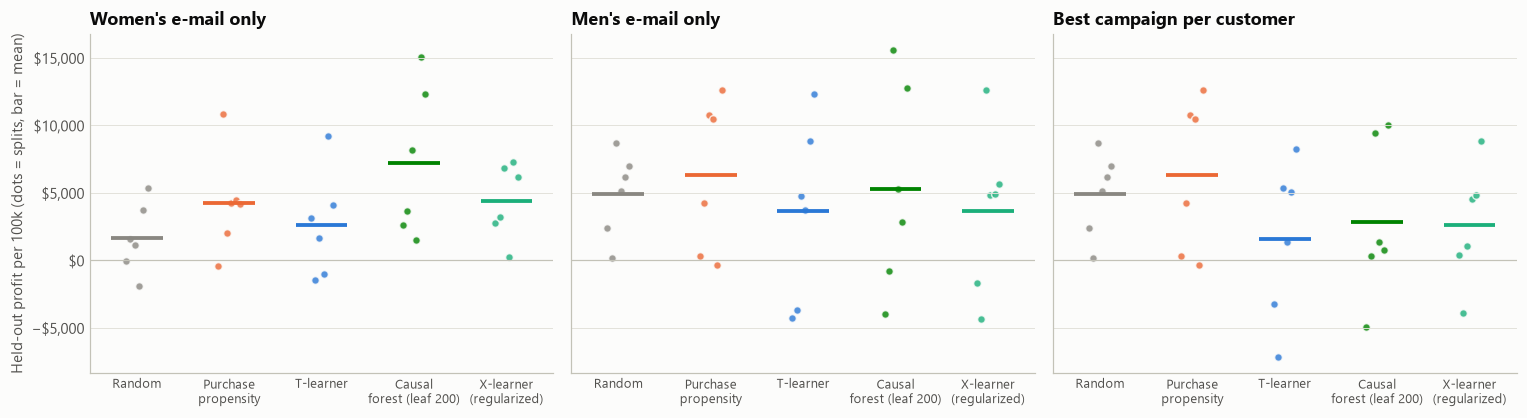

In [4]:
fig, axes = plt.subplots(1, 3, figsize=(14, 3.9), sharey=True)
for ax, option in zip(axes, scenario.CAMPAIGN_OPTIONS):
    for j, name in enumerate(POLICIES):
        v = rep[(rep.option == option) & (rep.policy == name)].profit.to_numpy()
        ax.scatter(np.full(len(v), j) + np.linspace(-0.12, 0.12, len(v)), v, color=P.color_for(name), s=26, alpha=0.8,
                   edgecolor=P.SURFACE, linewidth=1)
        ax.hlines(v.mean(), j - 0.28, j + 0.28, color=P.color_for(name), lw=2.5)
    ax.axhline(0, color=P.AXIS, lw=0.8)
    ax.set_xticks(range(len(POLICIES)), [p.replace(" ", "\n", 1) for p in POLICIES], fontsize=8.5)
    ax.set_title(scenario.CAMPAIGN_OPTIONS[option]); P.dollar(ax, "y", 0)
axes[0].set_ylabel("Held-out profit per 100k (dots = splits, bar = mean)")
fig.tight_layout(); P.savefig(fig, "06_repeated_splits"); plt.show()

### 1b · Is the selected policy's advantage consistent?

Paired differences for the selected policy (best campaign per customer) against each alternative, by split. The test sets of different splits overlap, so the splits are **not independent**. The pooled mean is a stability check, not a meta-analysis with a valid combined p-value. The table also shows the share of splits in which the selected policy wins.

In [5]:
comp = []
for name in ["Random", "Purchase propensity", "T-learner", CHALLENGER]:
    v, se = diffs[f"vs {name}"], diffs[f"vs {name} se"]
    comp.append({"comparison": f"{SELECTED} [best] − {name}", "mean": v.mean(), "min": v.min(), "max": v.max(),
                 "share of splits > 0": (v > 0).mean(), "typical within-split se": se.mean(),
                 "splits with z > 1.96": int((v / se > 1.96).sum())})
comp = pd.DataFrame(comp).set_index("comparison")
comp.style.format({"mean": P.money0, "min": P.money0, "max": P.money0, "share of splits > 0": "{:.0%}",
                   "typical within-split se": P.money0})

,mean,min,max,share of splits > 0,typical within-split se,splits with z > 1.96
comparison,,,,,,
X-learner (regularized) [best] − Random,"−$2,306","−$7,603","$1,861",17%,"$5,161",0
X-learner (regularized) [best] − Purchase propensity,"−$3,733","−$9,681","$5,123",33%,"$6,673",0
X-learner (regularized) [best] − T-learner,"$1,023","−$4,259","$3,586",67%,"$5,692",0
X-learner (regularized) [best] − Causal forest (leaf 200),−$206,"−$8,332","$5,318",50%,"$5,699",0


## 1c · Full-sample cross-fitted policy evaluation (most precise estimate)

Repeated 80/20 splits reuse overlapping test sets, so they show variability but cannot be pooled. The most precise single estimate uses **every customer exactly once as held-out data**:

* The full sample is split into 5 folds. Frozen models are fitted on 4 folds and score the 5th.
* The policy is formed **within** the held-out fold, with the budget scaled to the fold size.
* Each customer's profit contribution is valued with AIPW scores cross-fitted inside that fold.
* Contributions from all 64,000 customers are pooled into one estimate with a CLT interval.

**Caveat:** model *selection* (notebook 03) used the 80% development set, which overlaps these folds. The comparison between the two finalists could be mildly optimistic, but the comparison of a frozen policy against random or propensity targeting is not affected by this overlap.

In [6]:
cf_folds = data.assign_folds(df, np.ones(len(df), bool), n_folds=5, seed=config.SEED + 7)
SCEN = {"$3k budget": B, "no budget": None}

def fold_contributions(k):
    fit, sc = (cf_folds != k).to_numpy(), (cf_folds == k).to_numpy()
    frame = pd.DataFrame(index=X.index[sc])
    for key in scenario.ARM_ORDER:
        s = pipeline.fit_and_score(df, X, fit, sc, key, FROZEN, seed=config.SEED + k)
        for name in s:
            frame[f"{name}|{key}"] = s[name]
    G = pipeline.evaluation_scores(df, X, sc, seed=config.SEED + k)
    gm = G[scenario.ARM_ORDER].to_numpy()
    # campaign for non-dollar baselines: larger difference in means on the *training* folds
    tr = df.loc[fit]
    dev_ate = {a: tr.loc[tr.segment == config.CAMPAIGNS[a], "spend"].mean() - tr.loc[tr.segment == config.CONTROL, "spend"].mean()
               for a in scenario.ARM_ORDER}
    out = {}
    for option in scenario.CAMPAIGN_OPTIONS:
        base_arm = scenario.ARM_ORDER.index(option) if option != "best" else int(np.argmax([dev_ate[a] for a in scenario.ARM_ORDER]))
        for sname, budget in SCEN.items():
            cov = 1.0 if budget is None else min(1.0, budget / (C * POP))
            z = {"Random" if budget is not None else "Treat all": cov * (M * gm[:, base_arm] - C)}
            a_sel = None
            for name in ["T-learner", CHALLENGER, SELECTED]:
                a = scenario.uplift_policy(frame, name, option, M, C, budget, POP)
                z[name] = opt.profit_contributions(a, gm, M, C)
                if name == SELECTED:
                    a_sel = a
            pc = cov if budget is not None else float((a_sel >= 0).mean())
            a_p = opt.allocate_top_fraction(frame[f"Purchase propensity|{scenario.ARM_ORDER[base_arm]}"].to_numpy(), pc, base_arm)
            z["Purchase propensity"] = opt.profit_contributions(a_p, gm, M, C)
            z["_coverage_selected"] = np.full(len(gm), (a_sel >= 0).mean())
            out[(option, sname)] = pd.DataFrame(z, index=frame.index)
    return out

t0 = time.time()
parts = [fold_contributions(k) for k in range(5)]
print(f"cross-fitted evaluation done in {time.time() - t0:.0f}s")
pooled = {key: pd.concat([p[key] for p in parts]) for key in parts[0]}

rows = []
for (option, sname), Z in pooled.items():
    base = "Random" if "Random" in Z else "Treat all"
    for name in [base, "Purchase propensity", "T-learner", CHALLENGER, SELECTED]:
        r = evaluation.mean_ci(Z[name])
        row = {"option": scenario.CAMPAIGN_OPTIONS[option], "scenario": sname, "policy": name,
               "profit": r["estimate"] * POP, "ci_low": r["ci_low"] * POP, "ci_high": r["ci_high"] * POP}
        if name != SELECTED:
            d = evaluation.mean_ci(Z[SELECTED] - Z[name])
            row.update({"selected − this": d["estimate"] * POP, "diff_ci_low": d["ci_low"] * POP,
                        "diff_ci_high": d["ci_high"] * POP, "z": d["estimate"] / d["se"]})
        rows.append(row)
xfit = pd.DataFrame(rows).set_index(["scenario", "option", "policy"]).sort_index(level=[0, 1], sort_remaining=False)
xfit.to_csv(config.ARTIFACTS_DIR / "crossfit_policy_results.csv")
xfit.style.format({c: P.money0 for c in ["profit", "ci_low", "ci_high", "selected − this", "diff_ci_low", "diff_ci_high"]}
                  | {"z": "{:.2f}"}, na_rep="—").set_caption(
    f"Pooled held-out profit per 100k customers (all 64,000 customers, 5-fold cross-fitted). Selected = {SELECTED}")

cross-fitted evaluation done in 74s


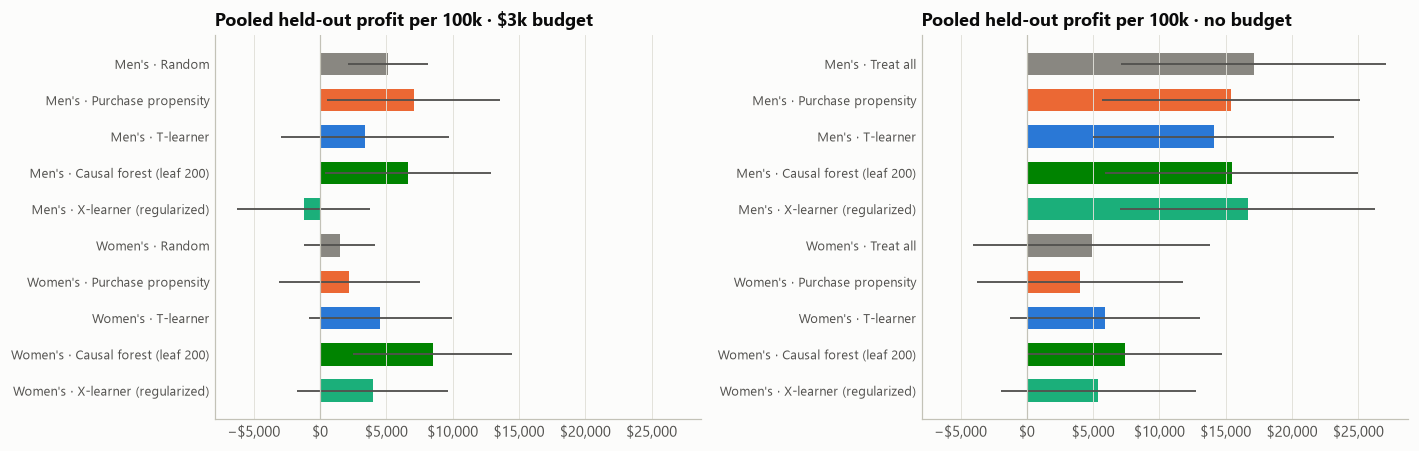

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.2), sharex=True)
for ax, sname in zip(axes, SCEN):
    sub = xfit.xs(sname, level="scenario").reset_index()
    sub = sub[sub.option.isin([scenario.CAMPAIGN_OPTIONS["womens"], scenario.CAMPAIGN_OPTIONS["mens"]])]
    labels = [f"{o.split(' ')[0]} · {p}" for o, p in zip(sub.option, sub.policy)]
    y = np.arange(len(sub))[::-1]
    ax.barh(y, sub.profit, color=[P.color_for(p) if p not in ("Random", "Treat all") else P.MUTED for p in sub.policy], height=0.62)
    ax.hlines(y, sub.ci_low, sub.ci_high, color=P.INK_2, lw=1.2)
    ax.axvline(0, color=P.AXIS, lw=0.8)
    ax.set_yticks(y, labels, fontsize=8.5); ax.grid(axis="y", visible=False); ax.grid(axis="x")
    P.dollar(ax, "x", 0); ax.set_title(f"Pooled held-out profit per 100k · {sname}")
fig.tight_layout(); P.savefig(fig, "06_crossfit_policy_profit"); plt.show()

### 1d · Paired comparisons for both finalists (pooled, all 64,000 customers)

In [8]:
def pair(Z, a, b):
    d = evaluation.mean_ci(Z[a] - Z[b])
    return {"diff": d["estimate"] * POP, "ci_low": d["ci_low"] * POP, "ci_high": d["ci_high"] * POP, "z": d["estimate"] / d["se"]}

prs = []
for (option, sname), Z in pooled.items():
    base = "Random" if "Random" in Z else "Treat all"
    for a in [CHALLENGER, SELECTED]:
        for b in [base, "Purchase propensity"]:
            prs.append({"scenario": sname, "option": scenario.CAMPAIGN_OPTIONS[option], "comparison": f"{a} − {b}", **pair(Z, a, b)})
prs = pd.DataFrame(prs).set_index(["scenario", "option", "comparison"])
prs.to_csv(config.ARTIFACTS_DIR / "crossfit_paired.csv")
prs.style.format({"diff": P.money0, "ci_low": P.money0, "ci_high": P.money0, "z": "{:.2f}"})

## 1e · Post-hoc: did the selection metric match the decision?

The pre-registered rule in notebook 03 ranked models by **AUGC averaged over campaigns**. That is a whole-curve ranking metric, and it is blind to calibration. The pooled evaluation shows the selected X-learner doing badly on the Men's e-mail under a budget, while the challenger does well.

Was this foreseeable **from development data alone**? The cell below re-scores the two finalists, using only the notebook 03 out-of-fold artifacts (no test data), on a *decision-matched* criterion:
1. profit of the budgeted decision (top 30%) under the default economics, averaged over campaigns;
2. a calibration gate: the BLP slope must be positive for each campaign.

This is explicitly **post hoc**. It is motivated by the result above and is reported as a lesson, not as a new selection.

In [9]:
g_dev = pd.read_csv(config.ARTIFACTS_DIR / "oof_gamma_spend.csv", index_col=0)
rows = []
for name in [SELECTED, CHALLENGER, "Purchase propensity"]:
    row = {"model": name, "dev AUGC (pre-registered)": sel["dev_mean_AUGC"][name]}
    profits = []
    for key in scenario.ARM_ORDER:
        o = pd.read_csv(config.ARTIFACTS_DIR / f"oof_all_{key}.csv", index_col=0)
        g = g_dev[key].loc[o.index].to_numpy()
        gain = evaluation.policy_gain(evaluation.top_k_mask(o[name].to_numpy(), 0.3), g)["estimate"]
        row[f"dev profit@30% {key}"] = (M * gain - C * 0.3) * POP
        profits.append(row[f"dev profit@30% {key}"])
        if name != "Purchase propensity":
            row[f"dev BLP {key}"] = evaluation.calibration_slope(o[name].to_numpy(), g)["slope"]
    row["dev profit@30% mean"] = np.mean(profits)
    rows.append(row)
posthoc = pd.DataFrame(rows).set_index("model")
dollar_cands = posthoc.drop(index="Purchase propensity")
RECOMMENDED = dollar_cands["dev profit@30% mean"].idxmax()
posthoc.style.format({c: (P.money0 if "profit" in c else "{:.3f}") for c in posthoc.columns}, na_rep="—")

,dev AUGC (pre-registered),dev profit@30% mens,dev BLP mens,dev profit@30% womens,dev BLP womens,dev profit@30% mean
model,,,,,,
X-learner (regularized),0.073,"$6,975",0.004,"$9,071",0.689,"$8,023"
Causal forest (leaf 200),0.071,"$11,228",0.311,"$7,929",0.790,"$9,578"
Purchase propensity,0.076,"$8,269",—,"$5,597",—,"$6,933"


In [10]:
display(P.md(f"""On development data alone, the decision-matched criterion prefers **{RECOMMENDED}**
(mean dev profit@30% {P.money0(dollar_cands.loc[RECOMMENDED, 'dev profit@30% mean'])} vs {P.money0(dollar_cands.drop(index=RECOMMENDED)['dev profit@30% mean'].iloc[0])}).
The selected X-learner's Men's BLP slope was already ≈ {posthoc.loc[SELECTED, 'dev BLP mens']:.3f}, meaning its Men's dollar effects carried no signal before any test data was seen.
**Lesson:** select uplift models on the metric of the decision they will drive (budgeted profit, per campaign), and gate on calibration. Whole-curve AUGC averaged over campaigns can hide a campaign where the model is useless."""))

On development data alone, the decision-matched criterion prefers **Causal forest (leaf 200)**
(mean dev profit@30% \$9,578 vs \$8,023).
The selected X-learner's Men's BLP slope was already ≈ 0.004, meaning its Men's dollar effects carried no signal before any test data was seen.
**Lesson:** select uplift models on the metric of the decision they will drive (budgeted profit, per campaign), and gate on calibration. Whole-curve AUGC averaged over campaigns can hide a campaign where the model is useless.

## 2 · Scorecard

In [11]:
ate = pd.read_csv(config.ARTIFACTS_DIR / "ate_table.csv").set_index(["campaign", "outcome"])
xf = xfit["profit"]
W, Mn, Bt = scenario.CAMPAIGN_OPTIONS["womens"], scenario.CAMPAIGN_OPTIONS["mens"], scenario.CAMPAIGN_OPTIONS["best"]
def pr(s, o, p): return P.money0(xf.loc[(s, o, p)])
def pc(s, o, comp):
    r = prs.loc[(s, o, comp)]
    return f"{P.money0(r['diff'])} (95% CI {P.money0(r.ci_low)} to {P.money0(r.ci_high)})"
bud, nob = "$3k budget", "no budget"
score = f"""
| # | Research question | Answer | Evidence |
|---|---|---|---|
| 1 | Average effect of each campaign? | **Both e-mails work.** Men's: +${ate.loc[('Mens E-Mail','spend'),'ATE']:.2f} spend and +{ate.loc[('Mens E-Mail','conversion'),'ATE']*100:.2f} pp conversion per customer. Women's: +${ate.loc[('Womens E-Mail','spend'),'ATE']:.2f} and +{ate.loc[('Womens E-Mail','conversion'),'ATE']*100:.2f} pp | Randomized difference in means; Holm-adjusted p < 0.002 for all six (NB01) |
| 2 | Does uplift targeting beat propensity targeting? | **Only where heterogeneity exists.** Women's e-mail at a \\$3k budget: causal forest {pr(bud, W, CHALLENGER)} vs propensity {pr(bud, W, 'Purchase propensity')} vs random {pr(bud, W, 'Random')} per 100k (paired vs random: {pc(bud, W, f'{CHALLENGER} − Random')}). Men's e-mail: no; propensity {pr(bud, Mn, 'Purchase propensity')}, causal forest {pr(bud, Mn, CHALLENGER)}, random {pr(bud, Mn, 'Random')} | Pooled 5-fold held-out evaluation (this NB); NB04 |
| 3 | How reliably can heterogeneous effects be estimated? | **Weakly for spend, well for visits.** About 90% of individual causal-forest intervals include 0. Unregularized learners are over-dispersed (BLP ≪ 1). Regularized forest and X-learner are calibrated for Women's. **No model learns Men's spend heterogeneity** | NB03 §3, §4; NB01 Wald test |
| 4 | Which policy maximizes profit? | **No budget cap: send the Men's e-mail to everyone** ({pr(nob, Mn, 'Treat all')} per 100k, the highest of any policy). **With a \\$3k cap:** a causal-forest-targeted Women's e-mail ({pr(bud, W, CHALLENGER)}) and propensity-targeted Men's e-mail ({pr(bud, Mn, 'Purchase propensity')}) are statistically tied. The pre-registered "best campaign per customer" X-learner policy ({pr(bud, Bt, SELECTED)}) is **not** recommended | Pooled evaluation (this NB) |
| 5 | How sensitive are the conclusions? | **Very sensitive to sample size and to the selection metric.** A single 12.8k test split cannot separate policies (CIs ≈ ±\\$10k), and split-to-split SDs are \\$3–8k. Selecting on budgeted profit instead of AUGC would have chosen {RECOMMENDED} from dev data alone | Repeated splits (§1), post-hoc §1e, NB04 heatmaps |
"""
display(P.md(score))


| # | Research question | Answer | Evidence |
|---|---|---|---|
| 1 | Average effect of each campaign? | **Both e-mails work.** Men's: +\$0.77 spend and +0.68 pp conversion per customer. Women's: +\$0.42 and +0.31 pp | Randomized difference in means; Holm-adjusted p < 0.002 for all six (NB01) |
| 2 | Does uplift targeting beat propensity targeting? | **Only where heterogeneity exists.** Women's e-mail at a \$3k budget: causal forest \$8,482 vs propensity \$2,214 vs random \$1,469 per 100k (paired vs random: \$7,013 (95% CI \$2,363 to \$11,664)). Men's e-mail: no; propensity \$7,059, causal forest \$6,650, random \$5,131 | Pooled 5-fold held-out evaluation (this NB); NB04 |
| 3 | How reliably can heterogeneous effects be estimated? | **Weakly for spend, well for visits.** About 90% of individual causal-forest intervals include 0. Unregularized learners are over-dispersed (BLP ≪ 1). Regularized forest and X-learner are calibrated for Women's. **No model learns Men's spend heterogeneity** | NB03 §3, §4; NB01 Wald test |
| 4 | Which policy maximizes profit? | **No budget cap: send the Men's e-mail to everyone** (\$17,102 per 100k, the highest of any policy). **With a \$3k cap:** a causal-forest-targeted Women's e-mail (\$8,482) and propensity-targeted Men's e-mail (\$7,059) are statistically tied. The pre-registered "best campaign per customer" X-learner policy (−\$281) is **not** recommended | Pooled evaluation (this NB) |
| 5 | How sensitive are the conclusions? | **Very sensitive to sample size and to the selection metric.** A single 12.8k test split cannot separate policies (CIs ≈ ±\$10k), and split-to-split SDs are \$3–8k. Selecting on budgeted profit instead of AUGC would have chosen Causal forest (leaf 200) from dev data alone | Repeated splits (§1), post-hoc §1e, NB04 heatmaps |


## 3 · Headline results file

Every number in the README and the research report is read from `reports/results.json`, which this cell writes. No result is typed by hand.

In [12]:
primary = pd.read_csv(config.ARTIFACTS_DIR / "test_policy_results.csv").set_index(["option", "policy"])
paired_primary = pd.read_csv(config.ARTIFACTS_DIR / "test_paired_comparisons.csv")
results = {
    "generated": time.strftime("%Y-%m-%d"),
    "selected_model": SELECTED, "challenger_model": CHALLENGER,
    "assumptions": {"margin": M, "cost_per_email": C, "budget_per_100k": B, "population": POP},
    "ate": {f"{c}|{o}": {k: float(ate.loc[(c, o), k]) for k in ["ATE", "ci_low", "ci_high", "rel_lift", "p_holm"]}
            for c, o in ate.index},
    "dev_mean_AUGC": sel["dev_mean_AUGC"],
    "primary_test": {f"{o}|{p}": {k: float(primary.loc[(o, p), k]) for k in ["coverage", "profit", "profit_ci_low", "profit_ci_high", "mens_share"]}
                     for o, p in primary.index},
    "primary_paired": paired_primary.to_dict(orient="records"),
    "repeated_splits": {"seeds": seeds, "mean_profit": {f"{o}|{p}": float(v) for (o, p), v in pivot["mean"].items()},
                        "sd_profit": {f"{o}|{p}": float(v) for (o, p), v in pivot["sd across splits"].items()},
                        "paired": comp.reset_index().to_dict(orient="records")},
    "crossfit": xfit.reset_index().to_dict(orient="records"),
    "crossfit_paired": prs.reset_index().to_dict(orient="records"),
    "recommended_model": RECOMMENDED,
    "posthoc_selection": posthoc.reset_index().to_dict(orient="records"),
    "test_no_budget": pd.read_csv(config.ARTIFACTS_DIR / "test_no_budget.csv").to_dict(orient="records"),
    "test_ranking": pd.read_csv(config.ARTIFACTS_DIR / "test_ranking_metrics.csv").to_dict(orient="records"),
}
(ROOT / "reports").mkdir(exist_ok=True)
with open(ROOT / "reports" / "results.json", "w") as f:
    json.dump(results, f, indent=2, default=float)
print("wrote reports/results.json")

wrote reports/results.json


## 4 · Reproducibility record

In [13]:
raw = data.find_data_file()
env = {
    "python": platform.python_version(), "platform": platform.platform(),
    **{p: version(p) for p in ["numpy", "pandas", "scipy", "scikit-learn", "statsmodels", "econml", "matplotlib", "plotly", "streamlit"]},
}
record = {
    "data_file": str(raw.relative_to(ROOT)),
    "data_sha256": hashlib.sha256(raw.read_bytes()).hexdigest(),
    "rows": len(df), "split_seed": config.SEED, "robustness_seeds": config.ROBUSTNESS_SEEDS,
    "split_fractions": config.SPLIT_FRACTIONS, "n_folds": config.N_FOLDS,
    "environment": env,
    "artifacts": {p.name: p.stat().st_size for p in sorted(config.ARTIFACTS_DIR.iterdir())},
}
with open(ROOT / "reports" / "reproducibility.json", "w") as f:
    json.dump(record, f, indent=2)
pd.Series({**{k: v for k, v in record.items() if k not in ("environment", "artifacts")}, **env}).to_frame("value")

,value
data_file,Data\Kevin_Hillstrom_MineThatData.csv
data_sha256,0e5893329d8b93cefecc571777672028290ab698657180...
rows,64000
split_seed,42
robustness_seeds,"[7, 11, 23, 101, 2024]"
split_fractions,"{'dev': 0.8, 'test': 0.2}"
n_folds,5
python,3.11.9
platform,Windows-10-10.0.26200-SP0
numpy,2.2.6


In [14]:
res = subprocess.run([sys.executable, "-m", "pytest", "-q", "--no-header", "-p", "no:cacheprovider"],
                     cwd=ROOT, capture_output=True, text=True)
print(res.stdout[-1500:])
assert res.returncode == 0, res.stderr

.................................                                        [100%]
33 passed in 7.64s



## 5 · Definition of done

| Item | Status | Where |
|---|---|---|
| Data source and terms documented | ✅ | README · Data |
| Treatment and control labels verified from the data | ✅ | `data.validate`, NB01 |
| Pre-treatment features separated from outcomes | ✅ | `data.build_features`, `tests/test_data.py`, NB05 artifact contract |
| ATEs with uncertainty intervals | ✅ | NB01 (Welch, bootstrap, permutation, Lin) |
| Propensity, random and broad baselines | ✅ | NB02 |
| Advanced uplift models evaluated | ✅ | NB03 (S/X/DR-learner, causal forest, calibrated propensity) |
| Model selection and final evaluation on separate data | ✅ | 5-fold CV on dev (NB02–03); test touched only in NB04 |
| Policy values and economics reported with assumptions | ✅ | NB04, dashboard |
| Reproducible from documented instructions | ✅ | README · Reproduce; this notebook |
| Dashboard and report distinguish measured findings from simulations | ✅ | evidence labels in app; NB05 |

## 6 · Limitations

* **External validity.** One retailer, one two-week window in 2008. Effects and costs today will differ.
* **Short outcome window.** Spend is measured over two weeks. Long-run effects (fatigue, unsubscribes, later purchases) are unobserved and are only proxied by the per-e-mail cost.
* **Noisy KPI.** With 0.9% buyers, spend-based policy comparisons have wide intervals. Differences between good targeting policies are not statistically distinguishable at this sample size.
* **Economics are assumptions.** Margin, cost and budget are inputs. The dashboard shows how conclusions move with them.
* **Estimates, not guarantees.** Held-out policy values are unbiased estimates for this population. A production rollout should run the policy against a randomized holdout, for example 10% random / 90% policy, and monitor realized lift.